In [1]:
import torch
from torch import nn
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

print(torch.__version__)
print(torchvision.__version__) 

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.2.2
0.17.2


In [2]:
from torchvision import datasets
train_data = datasets.FashionMNIST(
    root = "data",
    train = True,
    download = True,
    transform = torchvision.transforms.ToTensor(),
    target_transform = None
)

test_data = datasets.FashionMNIST(
    root = "data",
    train = False,
    download = True,
    transform = ToTensor(),
    target_transform = None
)

In [3]:
import os
print(os.getcwd())

/Users/mac/Desktop


In [4]:
len(train_data) , len(test_data)

(60000, 10000)

In [5]:
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [6]:
class_names = train_data.classes
class_names # 9 refers to Ankle boot

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [7]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [8]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [9]:
print(image.shape) # (C, H, W), it has 1 color channel because it is in black and white data set
print(label) # ما الو شيب لانو رقم int
print(class_names[label])

torch.Size([1, 28, 28])
9
Ankle boot


image shape :torch.Size([1, 28, 28])


Text(0.5, 1.0, '9')

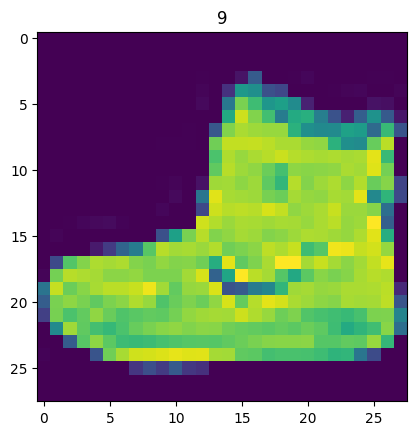

In [10]:
import matplotlib.pyplot as plt

image, label = train_data[0]
print(f"image shape :{image.shape}")
plt.imshow(image.squeeze())
plt.title(label)
#image

Text(0.5, 1.0, 'Ankle boot')

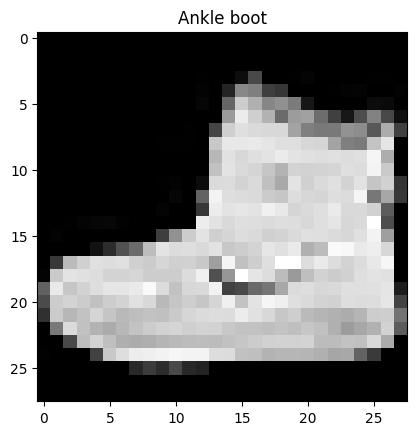

In [11]:
plt.imshow(image.squeeze(), cmap = "gray")
plt.title(class_names[label])

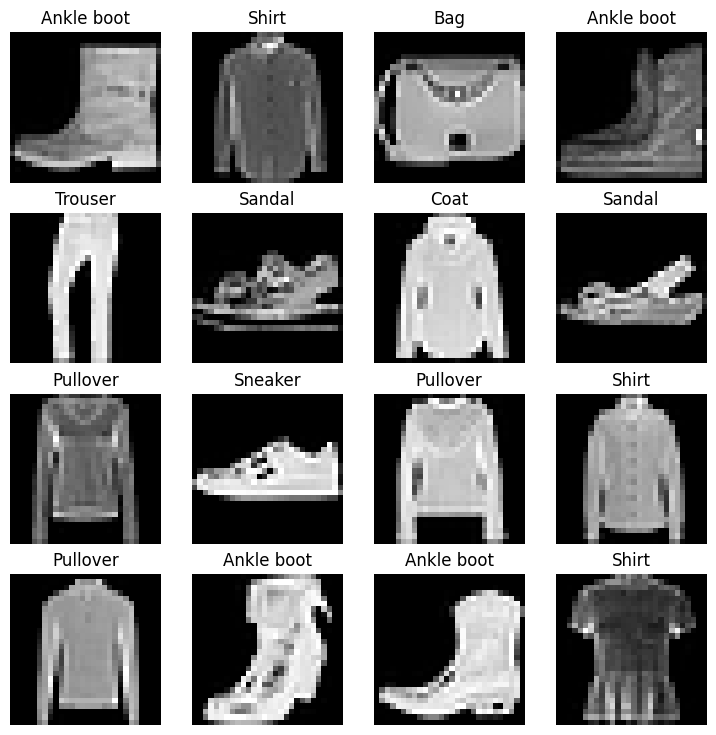

In [ ]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.gca().set_axis_off()  #  لإخفاء المحاور

In [13]:
train_data #pytorch dataset form

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [14]:
test_data #pytorch dataset form

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [15]:
# turn the data into batches
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader = DataLoader(dataset = train_data,
                              batch_size = BATCH_SIZE,
                              shuffle = True)

test_dataloader = DataLoader(dataset = test_data,
                             batch_size = BATCH_SIZE,
                             shuffle = False)

train_dataloader, test_dataloader


(<torch.utils.data.dataloader.DataLoader at 0x125590860>,
 <torch.utils.data.dataloader.DataLoader at 0x1251da330>)

In [16]:
len(train_dataloader), len(test_dataloader)

(1875, 313)

In [17]:
60000/32 # 1875 is the number of batches

1875.0

In [18]:
10000/32 # rounded up

312.5

In [19]:
train_features_batch, train_labels_batch = next(iter(train_dataloader)) #يقوم بتحويل الـ DataLoader إلى كائن يمكننا التكرار أو السحب منه (Iterator).
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 8, label size: torch.Size([])


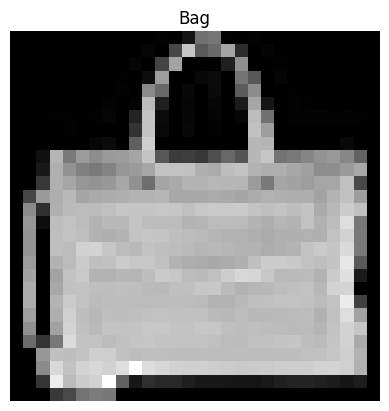

In [20]:
# Show a sample
#torch.manual_seed(42)
random_idx = torch.randint(
    0, len(train_features_batch), size=[1]
).item()  #
img, label = (
    train_features_batch[random_idx],
    train_labels_batch[random_idx],
)  
plt.imshow(img.squeeze(), cmap="gray")  
plt.title(class_names[label])  
plt.gca().set_axis_off() 
print(f"Image size: {img.shape}")  
print(f"Label: {label}, label size: {label.shape}")  

### building model

In [21]:
flatten_model = nn.Flatten() #الطبقات الخطية في الشبكات العصبية لا تفهم الصور ثنائية الأبعاد، بل تتطلب بيانات على شكل خط واحد ممتد
#تحول الصورة من أبعاد إلى خط واحد طوله 784

x = train_features_batch[0]
print(x.shape)

output = flatten_model(x) # perform forward pass
print(output.shape)

torch.Size([1, 28, 28])
torch.Size([1, 784])


In [22]:
output.squeeze() # one big vector

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0039, 0.0039, 0.0000, 0.0000, 0.0078, 0.0078,
        0.0000, 0.0000, 0.0039, 0.0078, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.2863, 0.0000, 0.0000, 0.0078, 

In [23]:
28*28

784

In [24]:
#Baseline Model
from torch import nn
class FashionMNISTModelV0(nn.Module):
    def __init__(self,
               input_shape : int,
               hidden_units :int,
               output_shape :int):
        super().__init__()
        self.layer_stack = nn.Sequential(nn.Flatten(),
                                         nn.Linear(in_features = input_shape, out_features = hidden_units),
                                         nn.Linear(in_features = hidden_units, out_features = output_shape))
        
    def forward(self, x):
        return self.layer_stack(x)

In [25]:
torch.manual_seed(42)
model_0 = FashionMNISTModelV0(input_shape = 784, #28*28
                              hidden_units = 10,
                              output_shape = len(class_names))

In [26]:
model_0

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [27]:
dummy_x = torch.rand([1, 1, 28, 28])
model_0(dummy_x) # the output is logits

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [28]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

In [29]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.1)

In [30]:
#function to time our experiments
from timeit import default_timer as timer
def print_train_time(start :float,
                     end : float):
    
    total_time = end - start
    print(total_time)
    return total_time

In [31]:
start_time = timer()
#some code
end_time = timer()
print_train_time(start=start_time, end=end_time)

4.471199645195156e-05


4.471199645195156e-05

In [32]:
def accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred))*100
    return acc

In [33]:
from tqdm.auto import tqdm

torch.manual_seed(42)
train_time_start_on_cpu = timer()

epochs = 3

for epoch in tqdm(range(epochs)): #epochs loop
    print(f"epoch: {epoch}")
    #training
    train_loss = 0
    for batch, (X, y) in enumerate(train_dataloader): #batches loop
        model_0.train()
        y_pred = model_0(X)
        loss = loss_fn(y_pred, y) 
        train_loss += loss #calculate the loss values every batch (مجموع أخطاء كل الدفعات مجتمعة)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step() #optimize per batch rather than per epoch
        
        if batch % 400 == 0:
            print(f"looked at {batch*len(X)} / {len(train_dataloader.dataset)} samples") #"عداد تقدم رقمي" يظهر لكِ كل 400 دفعة ليخبركِ بمدى تقدم النموذج وكم نسبة الصور التي أنجزها من الـ 60,000 صورة خلال هذه الدورة!
            
    train_loss /= len(train_dataloader) #average loss per epoch
    
    #testing
    test_loss, test_acc = 0, 0
    model_0.eval()
    with torch.inference_mode():
        for X_test, y_test in test_dataloader:
            test_pred = model_0(X_test)
            test_loss += loss_fn(test_pred, y_test)
            test_acc += accuracy(y_true=y_test, y_pred=test_pred.argmax(dim=1)) #our raw output is logits and we want it to be as the same format as y_test which is labels
            
  
        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.4f} | Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end=train_time_end_on_cpu)

  0%|          | 0/3 [00:00<?, ?it/s]

epoch: 0


looked at 0 / 60000 samples
looked at 12800 / 60000 samples
looked at 25600 / 60000 samples
looked at 38400 / 60000 samples
looked at 51200 / 60000 samples


 33%|███▎      | 1/3 [00:09<00:18,  9.30s/it]


Train loss: 0.5904 | Test loss: 0.5095 | Test acc: 82.0387
epoch: 1
looked at 0 / 60000 samples
looked at 12800 / 60000 samples
looked at 25600 / 60000 samples
looked at 38400 / 60000 samples
looked at 51200 / 60000 samples


 67%|██████▋   | 2/3 [00:18<00:09,  9.18s/it]


Train loss: 0.4763 | Test loss: 0.4799 | Test acc: 83.1969
epoch: 2
looked at 0 / 60000 samples
looked at 12800 / 60000 samples
looked at 25600 / 60000 samples
looked at 38400 / 60000 samples
looked at 51200 / 60000 samples


100%|██████████| 3/3 [00:27<00:00,  9.23s/it]


Train loss: 0.4550 | Test loss: 0.4766 | Test acc: 83.4265
27.71704758699343


In [34]:
next(model_0.parameters()).device

device(type='cpu')

In [35]:
def eval_model(model : torch.nn.Module,
               data_loader : torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               accuracy):
    
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in tqdm(data_loader):
            y_pred = model(X)
            loss += loss_fn(y_pred, y)
            acc += accuracy(y, y_pred.argmax(dim=1))
        
        loss /= len(data_loader)
        acc /= len(data_loader)
        
    return({"model_name" : model.__class__.__name__,
            "model_loss" : loss.item(),
            "model_acc" : acc})

In [36]:
model_0_results = eval_model(model = model_0,
                             data_loader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy = accuracy)
model_0_results

  0%|          | 0/313 [00:00<?, ?it/s]

100%|██████████| 313/313 [00:01<00:00, 233.04it/s]


{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [37]:
#create a model with non-linear and linear layers

class FashionMNISTModelV1(nn.Module):
    def __init__(self,
                 input_shape : int,
                 hidden_units : int,
                 output_shape : int):
        super().__init__()
        self.layer_stack = nn.Sequential(nn.Flatten(),
                                    nn.Linear(in_features = input_shape, out_features = hidden_units),
                                    nn.ReLU(),
                                    nn.Linear(in_features = hidden_units, out_features = output_shape),
                                    nn.ReLU())
    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)


In [38]:
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape = 784, #the output of flatten layer
                              hidden_units = 10,
                              output_shape = len(class_names))
model_1

FashionMNISTModelV1(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

In [39]:
model_1.parameters()

<generator object Module.parameters at 0x125b2f680>

In [40]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_1.parameters(),
                            lr = 0.1)

In [41]:
#create training loop function

def train_step(model : torch.nn.Module,
               data_loader : torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               optimizer : torch.optim.Optimizer,
               accuracy):
        
            train_loss, train_acc = 0, 0
            
            model.train()
            
            for batch, (X, y) in enumerate(data_loader): 
              y_pred = model(X)
              loss = loss_fn(y_pred, y) 
              train_loss += loss.item()
              train_acc += accuracy(y, y_pred.argmax(dim=1))
              optimizer.zero_grad()
              loss.backward()
              optimizer.step()
                
            train_loss /= len(data_loader)
            train_acc /= len(data_loader)
            
            print(f"train loss : {train_loss:.5f} | train acc : {train_acc:.2f}%")
    

In [42]:
#create testing loop function

def test_step(model : torch.nn.Module,
              data_loader : torch.utils.data.DataLoader,
              loss_fn : torch.nn.Module,
              accuracy):
    
    test_loss, test_acc = 0, 0
    
    model.eval()
    
    with torch.inference_mode():
        for X, y in data_loader:
            test_pred = model(X )
            test_loss += loss_fn(test_pred, y).item()
            test_acc += accuracy(y, test_pred.argmax(dim=1))
            
        test_loss /= len(data_loader)
        test_acc /= len(data_loader)
        
        print(f"test loss : {test_loss:.5f} | test acc : {test_acc:.2f}%")

In [43]:
from timeit import default_timer as timer

epochs = 3

train_time_start = timer()

for epoch in tqdm(range(epochs)):
    print(f"epoch : {epoch}")
    train_step(model = model_1, 
               data_loader = train_dataloader,
               loss_fn = loss_fn,
               optimizer = optimizer,
               accuracy = accuracy)
    test_step(model = model_1,
              data_loader = test_dataloader,
              loss_fn = loss_fn,
              accuracy = accuracy)
    
train_time_end = timer()

total_train_time_model_1 = print_train_time(start = train_time_start,
                                            end = train_time_end)
    
    

  0%|          | 0/3 [00:00<?, ?it/s]

epoch : 0
train loss : 1.05878 | train acc : 62.19%


 33%|███▎      | 1/3 [00:24<00:48, 24.40s/it]

test loss : 0.99506 | test acc : 64.13%
epoch : 1
train loss : 0.91331 | train acc : 66.40%


 67%|██████▋   | 2/3 [00:33<00:15, 15.57s/it]

test loss : 0.90508 | test acc : 66.86%
epoch : 2
train loss : 0.87982 | train acc : 67.24%


100%|██████████| 3/3 [00:43<00:00, 14.54s/it]

test loss : 0.89476 | test acc : 66.46%
43.61445476800145


In [44]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [45]:
total_train_time_model_0

27.71704758699343

In [46]:
model_1_results = eval_model(model = model_1,
                            data_loader = test_dataloader,
                            loss_fn = loss_fn,
                            accuracy = accuracy)
model_1_results

100%|██████████| 313/313 [00:01<00:00, 198.84it/s]


{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.8947635889053345,
 'model_acc': 66.46365814696486}

In [47]:
class FashionMNISTModelV2(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        
        #لاستخراج الميزات
        self.conv_block_1 = nn.Sequential( 
            nn.Conv2d(in_channels = input_shape, out_channels = hidden_units, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),#activation layer
            nn.Conv2d(in_channels = hidden_units, out_channels = hidden_units, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2) #تقوم الشبكة بضغط الصورة وتصغير حجمها (إلى النصف تقريباً) لتقليل كمية البيانات والتركيز على الأساسيات دون تفاصيل زائدة مزعجة.
        )
        
        #لاستخراج الميزات المعقدة
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels = hidden_units, out_channels = hidden_units, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels = hidden_units, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2)
        )
        
        #مرحلة التصنيف النهائي
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = hidden_units*7*7 #trick
                      , out_features = output_shape),
        )
        
    def forward(self, x):
        x = self.conv_block_1(x)
        #print(f"output shape of conv_block_1 {x.shape}")
        x = self.conv_block_2(x)
        #print(f"output shape of conv_block_2 {x.shape}")
        x = self.classifier(x)
        #print(f"output shape of classifier {x.shape}")
        return x

In [48]:
model_2 = FashionMNISTModelV2(input_shape = 1, #number of color channels
                         hidden_units = 10,
                         output_shape = len(class_names))

model_2

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [49]:
rand_image_tensor = torch.randn(1, 28, 28)
rand_image_tensor.shape

torch.Size([1, 28, 28])

In [50]:
10*7*7 #RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x490 and 10x10)

490

In [51]:
model_2(rand_image_tensor.unsqueeze(0))

tensor([[-0.0667,  0.0070,  0.0102, -0.0277,  0.0847,  0.0184,  0.0136,  0.0332,
         -0.0443, -0.0567]], grad_fn=<AddmmBackward0>)

In [52]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[-0.3012,  0.3277,  0.0879],
                        [ 0.1172, -0.2459,  0.2548],
                        [-0.2740, -0.1158, -0.2137]]],
              
              
                      [[[-0.1683,  0.0711, -0.3306],
                        [-0.3263,  0.0761,  0.1099],
                        [ 0.0048, -0.1266, -0.0932]]],
              
              
                      [[[-0.0460, -0.0676, -0.2062],
                        [ 0.2509,  0.0675, -0.2230],
                        [-0.0677, -0.2412, -0.1948]]],
              
              
                      [[[ 0.2532,  0.1018,  0.1460],
                        [-0.0432, -0.0832,  0.0431],
                        [-0.2368, -0.3317,  0.2343]]],
              
              
                      [[[ 0.0068,  0.2022,  0.2508],
                        [ 0.1458, -0.1139, -0.0611],
                        [-0.0174,  0.0199,  0.0130]]],
              
              
      

In [53]:
torch.manual_seed(42)

#create batch of images
image = torch.randn(size=(32, 3, 64, 64))
test_image = image[0]

print(image.shape)
print(test_image.shape)
print(test_image)

torch.Size([32, 3, 64, 64])
torch.Size([3, 64, 64])
tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [[-0.7978,  1.0261,  1.1465,  ...,  1.2134,  0.9354, -0.

In [54]:
#create a single conv layer
conv_layer = nn.Conv2d(in_channels = 3, #number of color channels
                     out_channels = 10, #number of filters (feature maps)
                     kernel_size = 3, #فلتر يمر عبر الصورة ليقوم بفحصها واستخراج الميزات (مثل الحواف والخطوط). or (3, 3)
                     stride = 1, #مقدار القفزة التي يتحركها الفلتر في كل مرة 
                     padding = 1) #إضافة إطار إضافي حول الصورة الأصلية (يظهر بالمربعات الرمادية المحيطة).

#pass the image through the layer
conv_output = conv_layer(test_image)
conv_output #الصورة مرت بعمليات حسابية بسبب مرورها على الطبقة وظهر الناتج بعد العمليات 

tensor([[[ 1.6446e-01, -6.2518e-01, -7.7713e-01,  ..., -3.2504e-01,
          -3.1604e-01,  4.5352e-01],
         [ 3.5455e-01, -2.8778e-01, -6.0596e-02,  ...,  6.6224e-01,
          -2.3216e-01,  7.7080e-01],
         [-4.5420e-02, -9.8911e-01, -4.0099e-01,  ..., -1.8552e-01,
          -5.7622e-01,  4.2301e-01],
         ...,
         [ 2.9288e-01, -1.4512e-01, -1.1566e-01,  ..., -3.6626e-01,
           3.5645e-01,  2.8384e-01],
         [ 2.0746e-01,  3.6096e-02,  1.5214e-01,  ..., -4.9680e-01,
          -7.2258e-01, -8.3858e-02],
         [-3.2457e-01, -3.2326e-01,  9.5475e-02,  ...,  5.9960e-01,
           3.2819e-01,  3.6604e-01]],

        [[ 1.2406e+00,  2.2794e-01, -1.8362e-01,  ..., -6.3520e-01,
          -7.5413e-01,  4.0612e-01],
         [ 4.1380e-01, -1.0853e+00, -1.6079e+00,  ..., -1.7643e+00,
           2.5263e-01,  3.8844e-01],
         [ 5.3442e-01, -8.2507e-01,  6.3866e-01,  ...,  4.8068e-01,
           8.4869e-01, -1.5706e-01],
         ...,
         [-5.6922e-03, -5

In [55]:
test_image.shape, conv_output.shape

(torch.Size([3, 64, 64]), torch.Size([10, 64, 64]))

In [56]:
#create a max pool layer
max_pool_layer = nn.MaxPool2d(kernel_size = 2) #أداة تصغير وضغط

#pass data through conv layer
test_image_through_conv = conv_layer(test_image)

#pass data through max pool layer
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv)

In [57]:
image.shape, test_image.shape, test_image_through_conv.shape, test_image_through_conv_and_max_pool.shape

(torch.Size([32, 3, 64, 64]),
 torch.Size([3, 64, 64]),
 torch.Size([10, 64, 64]),
 torch.Size([10, 32, 32]))

In [58]:
test_image_through_conv_and_max_pool

tensor([[[ 3.5455e-01, -5.6306e-02, -8.0488e-03,  ...,  9.3928e-01,
           6.6224e-01,  7.7080e-01],
         [ 1.8611e-01,  4.1832e-01, -2.9042e-03,  ...,  4.2515e-01,
           4.7459e-01,  4.2301e-01],
         [ 1.9298e-01,  8.5285e-01,  4.9459e-01,  ..., -1.0216e-01,
           4.2141e-01,  6.4681e-01],
         ...,
         [ 9.0690e-01, -4.8744e-02,  6.3528e-01,  ...,  8.6767e-01,
           2.7085e-01,  4.1853e-01],
         [ 2.9288e-01,  6.1783e-01,  1.5715e+00,  ...,  1.5053e-01,
           4.2594e-01,  3.5645e-01],
         [ 2.0746e-01,  2.3123e-01, -1.4222e-01,  ...,  6.5272e-01,
           5.9960e-01,  3.6604e-01]],

        [[ 1.2406e+00,  1.3346e-01,  6.6342e-01,  ...,  1.9963e-01,
           5.5463e-01,  4.0612e-01],
         [ 6.4927e-01,  6.3866e-01,  5.4939e-01,  ...,  5.9090e-01,
           5.8356e-01,  8.4869e-01],
         [ 4.1567e-01,  4.3793e-01,  8.4169e-01,  ...,  5.6342e-01,
           1.3965e+00,  1.0287e-01],
         ...,
         [ 1.3177e+00, -1

In [59]:
#another example on small data

random_tensor = torch.randn(size = (1, 1, 2, 2))
max_pool_output = max_pool_layer(random_tensor)

random_tensor.shape, max_pool_output.shape

(torch.Size([1, 1, 2, 2]), torch.Size([1, 1, 1, 1]))

In [60]:
random_tensor

tensor([[[[0.4963, 0.0045],
          [0.5534, 0.1379]]]])

In [61]:
max_pool_output # اخد الماكس بينهم واكبر رقم

tensor([[[[0.5534]]]])

In [62]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_2.parameters(),
                            lr = 0.1)

In [63]:
torch.manual_seed(42)
from timeit import default_timer as timer

epochs = 3

train_time_start_model_2 = timer()

for epoch in tqdm(range(epochs)):
    print(f"epoch : {epoch}")
    train_step(model = model_2,
               data_loader = train_dataloader,
               loss_fn = loss_fn,
               optimizer = optimizer,
               accuracy = accuracy)
    test_step(model = model_2,
              data_loader = test_dataloader,
              loss_fn = loss_fn,
              accuracy = accuracy)
    
train_time_end_model_2 = timer()

total_train_time_model_2 = print_train_time(start = train_time_start_model_2,
                                            end = train_time_end_model_2)

  0%|          | 0/3 [00:00<?, ?it/s]

epoch : 0
train loss : 0.69914 | train acc : 74.28%


 33%|███▎      | 1/3 [00:46<01:33, 46.79s/it]

test loss : 0.39560 | test acc : 85.80%
epoch : 1
train loss : 0.35875 | train acc : 87.18%


 67%|██████▋   | 2/3 [01:25<00:41, 41.76s/it]

test loss : 0.36056 | test acc : 86.62%
epoch : 2
train loss : 0.31794 | train acc : 88.48%


100%|██████████| 3/3 [02:18<00:00, 46.15s/it]

test loss : 0.32297 | test acc : 88.25%
138.44677622101153


In [64]:
model_2_results = eval_model(model = model_2,
                            data_loader = test_dataloader,
                            loss_fn = loss_fn,
                            accuracy = accuracy)
model_2_results

100%|██████████| 313/313 [00:03<00:00, 86.88it/s] 


{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.3229709565639496,
 'model_acc': 88.2488019169329}

In [65]:
model_1_results = eval_model(model = model_1,
                            data_loader = test_dataloader,
                            loss_fn = loss_fn,
                            accuracy = accuracy)
model_1_results

100%|██████████| 313/313 [00:02<00:00, 147.64it/s]


{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.8947635889053345,
 'model_acc': 66.46365814696486}

In [66]:
model_0_results = eval_model(model = model_0,
                            data_loader = test_dataloader,
                            loss_fn = loss_fn,
                            accuracy = accuracy)
model_0_results

100%|██████████| 313/313 [00:02<00:00, 123.53it/s]


{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [67]:
import pandas as pd

compare_results = pd.DataFrame([model_0_results,
                                model_1_results,
                                model_2_results])

compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,83.426518
1,FashionMNISTModelV1,0.894764,66.463658
2,FashionMNISTModelV2,0.322971,88.248802


In [68]:
compare_results["training time"] = [total_train_time_model_0,
                                    total_train_time_model_1,
                                    total_train_time_model_2]

compare_results

,model_name,model_loss,model_acc,training time
0,FashionMNISTModelV0,0.476639,83.426518,27.717048
1,FashionMNISTModelV1,0.894764,66.463658,43.614455
2,FashionMNISTModelV2,0.322971,88.248802,138.446776


Text(0, 0.5, 'model')

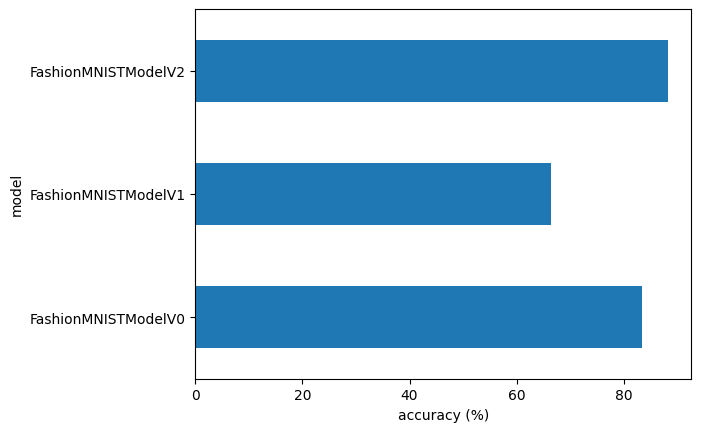

In [69]:
# Visualize our model results
compare_results.set_index("model_name")["model_acc"].plot(kind="barh")
plt.xlabel("accuracy (%)")
plt.ylabel("model")

In [70]:
#make evaluation with best model
def make_predictions(model: torch.nn.Module,
                     data: list):
    pred_probs = []
    model.eval()
    with torch.inference_mode():
        for sample in data:
            # Prepare the sample (add a batch dimension and pass to target device)
            sample = torch.unsqueeze(sample, dim=0)
            
            # Forward pass (model outputs raw logits)
            pred_logit = model(sample)
            
            # Get prediction probability (logit -> prediction probability)
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)
            
            # Get pred_prob off the GPU for further calculations
            pred_probs.append(pred_prob)
            
    # Stack the pred_probs to turn list into a tensor
    return torch.stack(pred_probs)

In [71]:
import random
#random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

# View the first sample shape
test_samples[0].shape

torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Ankle boot')

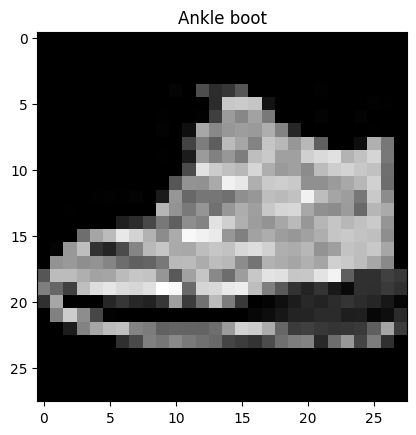

In [72]:
plt.imshow(test_samples[0].squeeze(), cmap="gray")
plt.title(class_names[test_labels[0]])

In [73]:
# Make predictions
pred_probs = make_predictions(model=model_2,
                              data=test_samples)

# View first two prediction probabilities
pred_probs[:2]

tensor([[3.1781e-06, 3.3117e-06, 6.9733e-06, 1.4710e-04, 4.1972e-05, 7.1546e-03,
         1.1544e-04, 6.1598e-02, 4.7900e-03, 9.2614e-01],
        [6.8291e-03, 9.5872e-04, 2.9246e-01, 8.8888e-05, 5.1597e-01, 4.0526e-04,
         1.8318e-01, 1.6296e-05, 2.0524e-05, 6.7667e-05]])

In [74]:
# Convert prediction probabilities to labels
pred_classes = pred_probs.argmax(dim=1)
pred_classes

tensor([9, 4, 9, 9, 6, 3, 1, 8, 2])

In [75]:
test_labels #same format

[9, 4, 9, 9, 6, 3, 1, 8, 2]

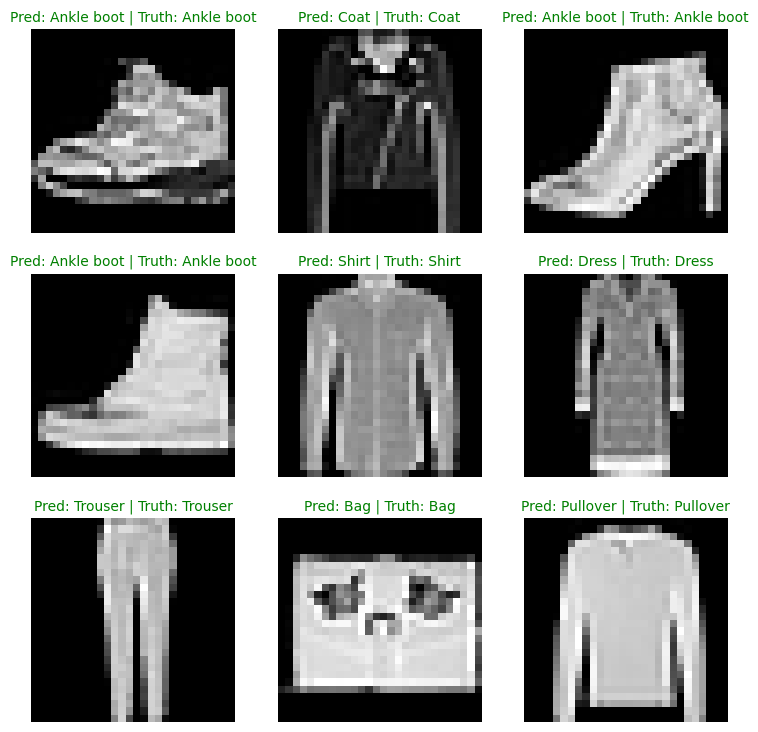

In [76]:
# Plot predictions
plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
    # Create subplot
    plt.subplot(nrows, ncols, i+1)
    
    # Plot the target image
    plt.imshow(sample.squeeze(), cmap="gray")
    
    # Find the prediction (in text form, e.g "Sandal")
    pred_label = class_names[pred_classes[i]]
    
    # Get the truth label (in text form)
    truth_label = class_names[test_labels[i]]
    
    # Create a title for the plot
    title_text = f"Pred: {pred_label} | Truth: {truth_label}"
    
    # Check for equality between pred and truth and change color of title text
    if pred_label == truth_label:
        plt.title(title_text, fontsize=10, c="g") # green text if prediction same as truth
    else:
        plt.title(title_text, fontsize=10, c="r")
        
    plt.axis("off")

In [77]:
import mlxtend
#مكتبة mlxtend (اختصار لـ Machine Learning Extensions) هي مكتبة برمجية في لغة بايثون مصممة لتكون أداة مساعدة ومكملة لمكتبات تعلم الآلة الشهيرة مثل Scikit-learn و Pandas و NumPy

In [78]:
mlxtend.__version__

'0.23.1'

In [79]:
# Import tqdm.auto
from tqdm.auto import tqdm

# 1. Make predictions with trained model
y_preds = []
model_2.eval()
with torch.inference_mode():
    for X, y in tqdm(test_dataloader, desc="Making predictions..."):
        # Do the forward pass
        y_logit = model_2(X)
        # Turn predictions from logits -> prediction probabilities -> prediction labels
        y_pred = torch.softmax(y_logit.squeeze(), dim=1).argmax(dim=1)
        # Put prediction on CPU for evaluation
        y_preds.append(y_pred)

# Concatenate list of predictions into a tensor
#print(y_preds)
y_pred_tensor = torch.cat(y_preds)
y_pred_tensor[:10]

Making predictions...: 100%|██████████| 313/313 [00:09<00:00, 34.52it/s]


tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

In [80]:
len(y_pred_tensor)

10000

In [81]:
import torchmetrics

In [82]:
y_pred_tensor[:10]

tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

In [83]:
test_data.targets

tensor([9, 2, 1,  ..., 8, 1, 5])

In [84]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix(num_classes = len(class_names), task="multiclass")
confmat_tensor = confmat(preds = y_pred_tensor,
                         target = test_data.targets)

confmat_tensor

tensor([[873,   2,   6,  23,   7,   0,  76,   0,  13,   0],
        [  3, 968,   0,  22,   3,   0,   3,   0,   1,   0],
        [ 18,   0, 716,   9, 168,   0,  88,   0,   1,   0],
        [ 27,   2,   4, 901,  30,   0,  35,   0,   1,   0],
        [  0,   1,  37,  37, 833,   0,  91,   0,   1,   0],
        [  0,   0,   0,   0,   0, 982,   0,  10,   1,   7],
        [168,   1,  43,  33,  85,   0, 659,   0,  11,   0],
        [  0,   0,   0,   0,   0,  19,   0, 963,   0,  18],
        [  3,   1,   1,   3,   6,   4,   7,   5, 970,   0],
        [  0,   0,   0,   0,   0,   6,   1,  34,   1, 958]])

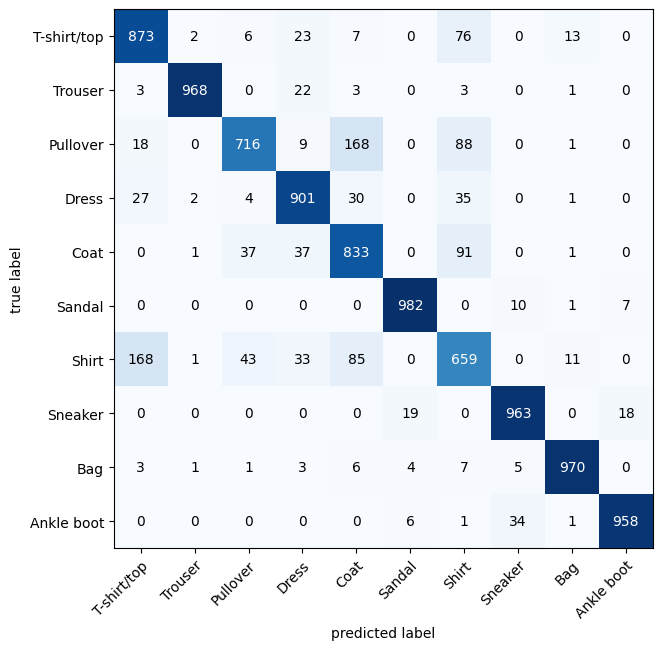

In [85]:
# 3. Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), # matplotlib likes working with numpy
    class_names=class_names,
    figsize=(10, 7)
)